# 1. Install and import

In [1]:
!pip -q install dice-ml


In [17]:
import numpy as np
import pandas as pd
import dice_ml
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 7

rng = np.random.default_rng(SEED)


# 2. Create a 40-feature synthetic loan dataset

In [5]:
n = 3000

# Six features used by the synthetic approval rule
signal = pd.DataFrame({
    "annual_income_k": rng.uniform(20, 120, n),       # EUR thousands
    "debt_k": rng.uniform(0, 60, n),                  # EUR thousands
    "credit_history_years": rng.integers(0, 26, n),
    "employment_years": rng.integers(0, 26, n),
    "savings_k": rng.uniform(0, 80, n),               # EUR thousands
    "monthly_payment_k": rng.uniform(0.1, 4.0, n),    # EUR thousands
})

# Thirty-four extra numeric features.
# Most are irrelevant to the synthetic decision; a few are correlated
# with core features to make the data less trivially independent.
extra = pd.DataFrame({
    f"extra_feature_{i:02d}": rng.normal(0, 1, n)
    for i in range(1, 35)
})

# Add some correlations to make the toy data a little more realistic.
extra["extra_feature_01"] = (
    signal["annual_income_k"] / 100 + rng.normal(0, 0.2, n)
)
extra["extra_feature_02"] = (
    signal["debt_k"] / 60 + rng.normal(0, 0.2, n)
)
extra["extra_feature_03"] = (
    signal["employment_years"] / 25 + rng.normal(0, 0.2, n)
)

X = pd.concat([signal, extra], axis=1)

assert X.shape[1] == 40

Define an intentionally simple synthetic approval rule. It uses income, debt, credit history, employment history, savings, and monthly payment; it does not use the 34 extra features.

In [6]:
score = (
    0.045 * X["annual_income_k"]
    - 0.070 * X["debt_k"]
    + 0.090 * X["credit_history_years"]
    + 0.060 * X["employment_years"]
    + 0.035 * X["savings_k"]
    - 0.80 * X["monthly_payment_k"]
    + rng.normal(0, 0.65, n)
)

y = (score > 3.3).astype(int)

df = X.copy()
df["approved"] = y

print("Rows:", len(df))
print("Features:", X.shape[1])
print("Approval rate:", round(y.mean(), 3))
display(df.head())

Rows: 3000
Features: 40
Approval rate: 0.41


,annual_income_k,debt_k,credit_history_years,employment_years,savings_k,monthly_payment_k,extra_feature_01,extra_feature_02,extra_feature_03,extra_feature_04,...,extra_feature_26,extra_feature_27,extra_feature_28,extra_feature_29,extra_feature_30,extra_feature_31,extra_feature_32,extra_feature_33,extra_feature_34,approved
0,82.509547,12.134100,19,0,20.922758,3.696641,0.675643,0.146928,-0.340463,-0.371858,...,-0.621646,-0.433936,1.158269,-0.029189,-0.327140,0.910528,0.060624,0.308285,1.094153,0
1,109.721380,48.846324,8,8,32.086234,0.657650,1.003679,0.974241,0.736924,1.259685,...,-0.010591,-0.137077,0.295088,1.230024,-0.151120,-0.155010,1.412094,-0.324633,-1.109652,1
2,97.568569,43.126753,21,6,52.794154,1.030476,1.206921,0.772287,0.186692,0.443702,...,-0.469907,1.830007,0.014512,2.276809,-0.499323,0.068562,2.431491,-0.366098,0.299174,1
3,42.520719,53.959540,3,18,71.185441,3.998349,0.725266,1.252604,0.775300,0.942742,...,-0.849167,0.753674,-0.238508,-1.231267,-0.191444,-0.520702,1.145270,-0.874757,-0.873898,0
4,50.016628,55.473219,0,11,65.289875,3.015153,0.403629,0.877369,0.585291,-0.867547,...,0.561720,0.105296,1.592905,-1.003176,0.556987,0.984172,0.592630,-0.098301,1.149702,0


# Dataset and approval overview

/tmp/ipykernel_735/2245032753.py:11: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  signal.hist(ax=axes[1], bins=20, figsize=(12, 8), layout=(2, 3),


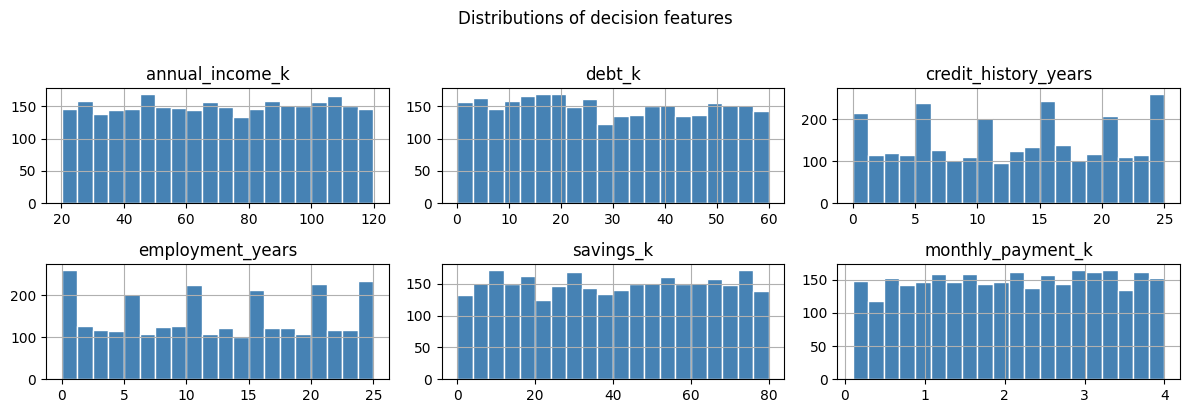

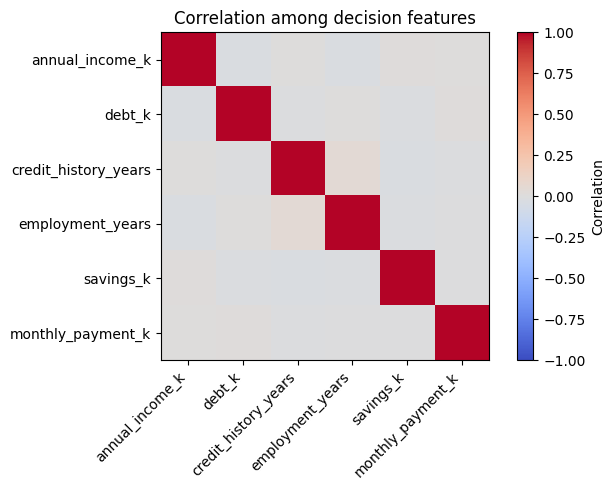

In [18]:
# Approval balance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df["approved"].value_counts().sort_index()
axes[0].bar(["Rejected (0)", "Approved (1)"], counts.values,
            color=["tomato", "seagreen"])
axes[0].set_title("Synthetic loan outcomes")
axes[0].set_ylabel("Number of applicants")

# Distributions of the six features used in the synthetic rule
signal.hist(ax=axes[1], bins=20, figsize=(12, 8), layout=(2, 3),
            color="steelblue", edgecolor="white")
plt.suptitle("Distributions of decision features", y=1.02)
plt.tight_layout()
plt.show()

# Correlation among the six decision features
corr = signal.corr()
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
ax.set_title("Correlation among decision features")
fig.colorbar(image, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

# 3. Train a model

In [8]:
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=SEED,
    stratify=y,
)

model = RandomForestClassifier(
    n_estimators=250,
    min_samples_leaf=5,
    random_state=SEED,
    class_weight="balanced",
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, predictions), 3))
print(classification_report(y_test, predictions, target_names=["rejected", "approved"]))

Test accuracy: 0.885
              precision    recall  f1-score   support

    rejected       0.90      0.91      0.90       442
    approved       0.87      0.85      0.86       308

    accuracy                           0.89       750
   macro avg       0.88      0.88      0.88       750
weighted avg       0.89      0.89      0.89       750



# Model performance

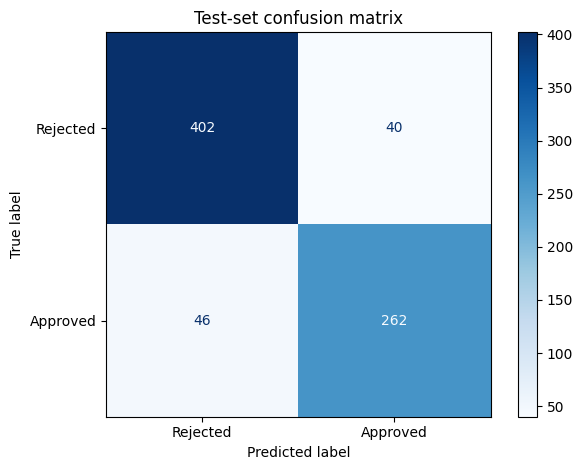

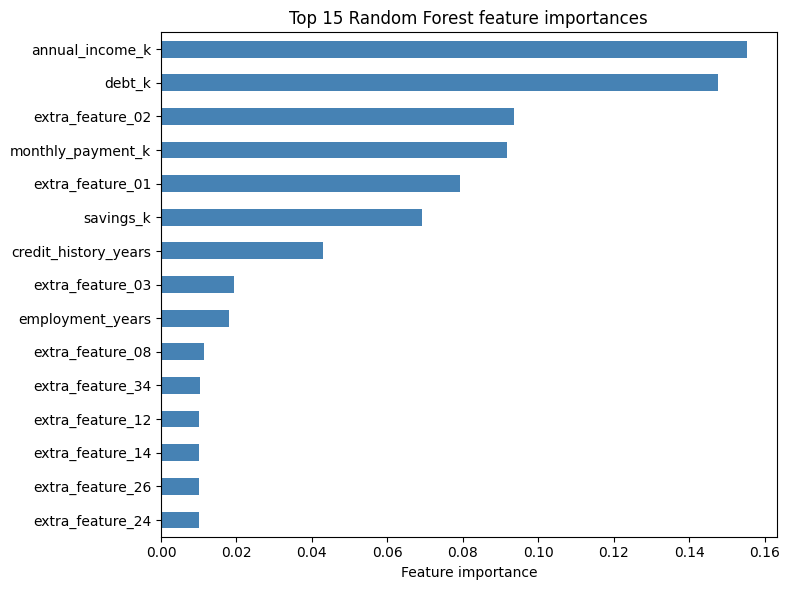

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    model,
    X_test,
    y_test,
    display_labels=["Rejected", "Approved"],
    cmap="Blues",
    values_format="d",
)
plt.title("Test-set confusion matrix")
plt.tight_layout()
plt.show()

# Top 15 Random Forest feature importances
importances = pd.Series(model.feature_importances_, index=X.columns)
top_importances = importances.sort_values().tail(15)

fig, ax = plt.subplots(figsize=(8, 6))
top_importances.plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Top 15 Random Forest feature importances")
ax.set_xlabel("Feature importance")
plt.tight_layout()
plt.show()

# 4. Select a rejected applicant

In [9]:
rejected_rows = X_test.loc[y_test[y_test == 0].index]
query = rejected_rows.iloc[[0]].copy()

print("Applicant features:")
display(query.T.rename(columns={query.index[0]: "value"}))

print("Predicted class:", int(model.predict(query)[0]))
print("Approval probability:", round(model.predict_proba(query)[0, 1], 3))

Applicant features:


,value
annual_income_k,98.730759
debt_k,47.020391
credit_history_years,16.000000
employment_years,7.000000
savings_k,61.908755
monthly_payment_k,2.185236
extra_feature_01,0.963109
extra_feature_02,0.649504
extra_feature_03,0.037438
extra_feature_04,-1.434834


Predicted class: 0
Approval probability: 0.405


# Inspect the rejected applicant

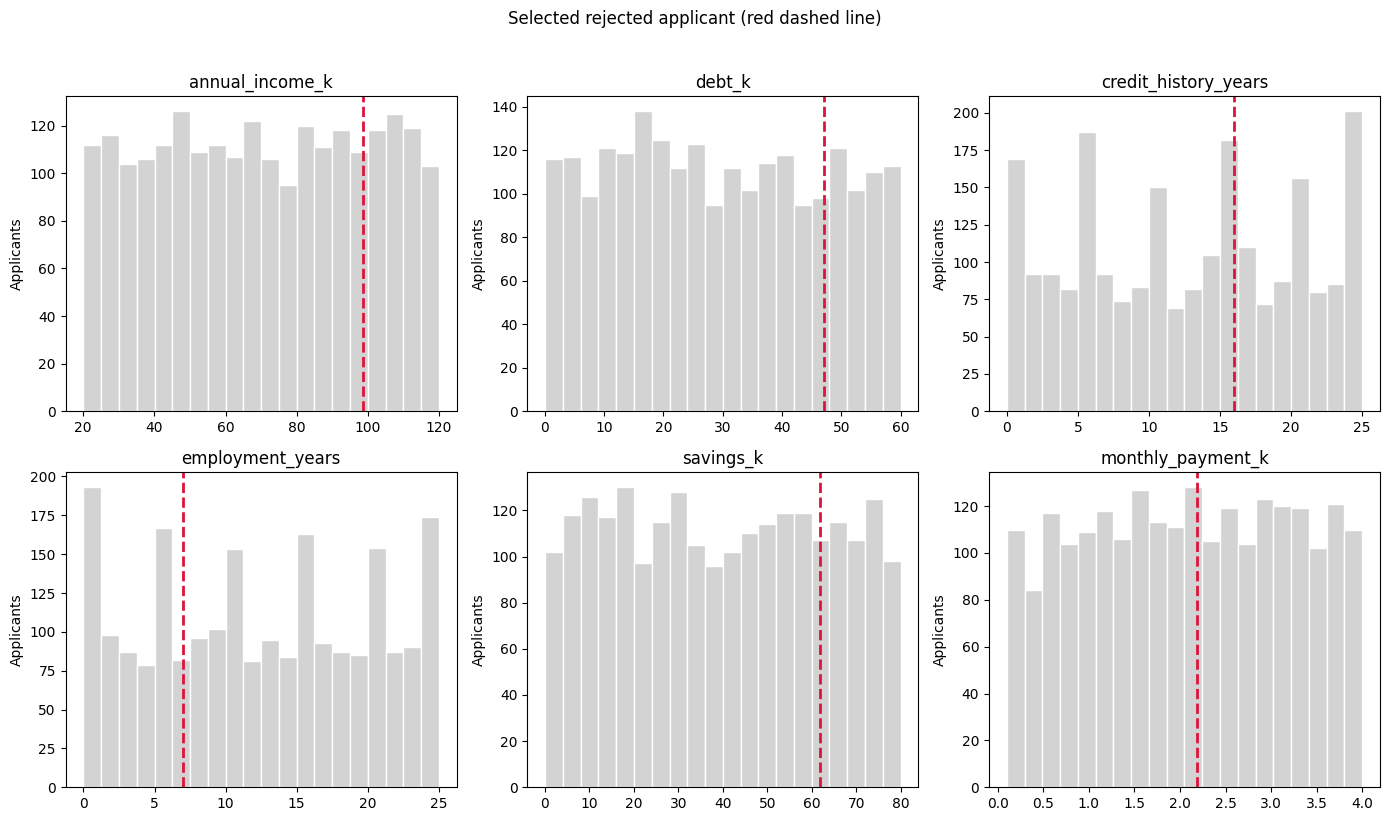

In [20]:
core_features = [
    "annual_income_k",
    "debt_k",
    "credit_history_years",
    "employment_years",
    "savings_k",
    "monthly_payment_k",
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for ax, feature in zip(axes, core_features):
    ax.hist(X_train[feature], bins=20, color="lightgray", edgecolor="white")
    applicant_value = query.iloc[0][feature]
    ax.axvline(applicant_value, color="crimson", linestyle="--", linewidth=2)
    ax.set_title(feature)
    ax.set_ylabel("Applicants")

fig.suptitle("Selected rejected applicant (red dashed line)", y=1.02)
plt.tight_layout()
plt.show()

# 5. Set up DiCE and generate counterfactuals

All features are numeric here, so list them as continuous. Restrict changes to the six features used by the synthetic rule; this provides a useful contrast with allowing all 40 features to vary.

In [10]:
train_for_dice = X_train.copy()
train_for_dice["approved"] = y_train

dice_data = dice_ml.Data(
    dataframe=train_for_dice,
    continuous_features=list(X.columns),
    outcome_name="approved",
)

dice_model = dice_ml.Model(
    model=model,
    backend="sklearn",
)

explainer = dice_ml.Dice(
    dice_data,
    dice_model,
    method="genetic",
)

actionable_features = [
    "annual_income_k",
    "debt_k",
    "credit_history_years",
    "employment_years",
    "savings_k",
    "monthly_payment_k",
]

counterfactuals = explainer.generate_counterfactuals(
    query,
    total_CFs=3,
    desired_class=1,
    features_to_vary=actionable_features,
    permitted_range={
        "annual_income_k": [20, 120],
        "debt_k": [0, 60],
        "credit_history_years": [0, 25],
        "employment_years": [0, 25],
        "savings_k": [0, 80],
        "monthly_payment_k": [0.1, 4.0],
    },
)

counterfactuals.visualize_as_dataframe(show_only_changes=True)

100%|██████████| 1/1 [00:00<00:00,  1.11it/s]

Query instance (original outcome : 0)


,annual_income_k,debt_k,credit_history_years,employment_years,savings_k,monthly_payment_k,extra_feature_01,extra_feature_02,extra_feature_03,extra_feature_04,...,extra_feature_26,extra_feature_27,extra_feature_28,extra_feature_29,extra_feature_30,extra_feature_31,extra_feature_32,extra_feature_33,extra_feature_34,approved
0,98.730759,47.02039,16,7,61.908756,2.185236,0.963109,0.649504,0.037438,-1.434834,...,-2.238074,-1.112354,0.387413,-0.377254,0.79562,0.93315,0.967298,0.89826,-0.387433,0



Diverse Counterfactual set (new outcome: 1)


,annual_income_k,debt_k,credit_history_years,employment_years,savings_k,monthly_payment_k,extra_feature_01,extra_feature_02,extra_feature_03,extra_feature_04,...,extra_feature_26,extra_feature_27,extra_feature_28,extra_feature_29,extra_feature_30,extra_feature_31,extra_feature_32,extra_feature_33,extra_feature_34,approved
0,102.722328,46.20832825,-,13.0,61.24635,1.592816591,-,-,-,-,...,-,-,-,-,-,-,-,-,-,1.0
0,103.402649,30.01908684,19.0,-,67.30118,3.373045683,-,-,-,-,...,-,-,-,-,-,-,-,-,-,1.0
0,100.447136,37.34625626,14.0,-,53.88242,0.233767599,-,-,-,-,...,-,-,-,-,-,-,-,-,-,1.0


# Visualize generated counterfactuals

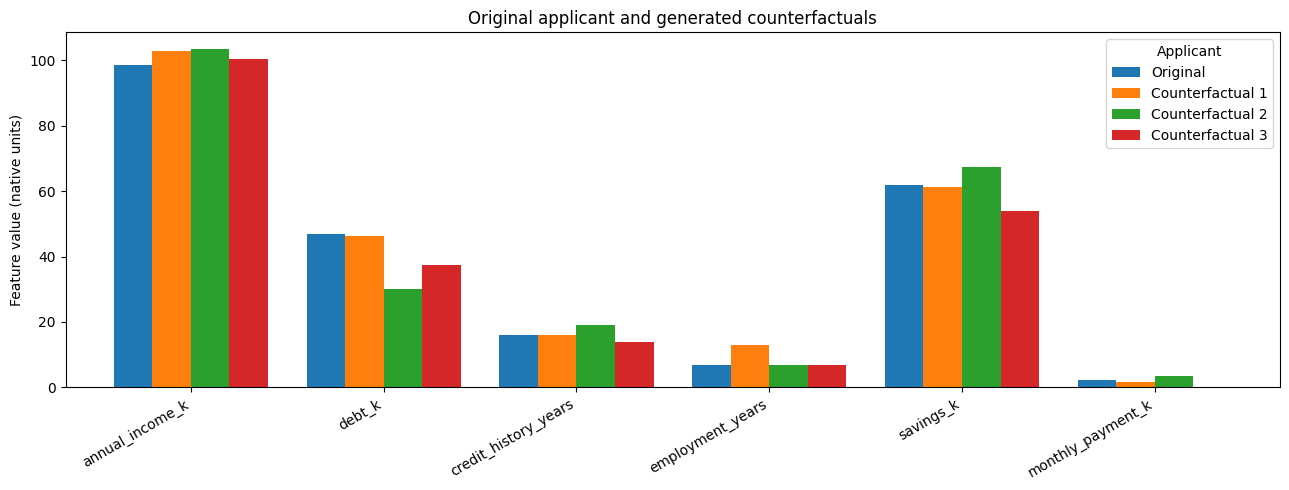

In [21]:
cf_df = counterfactuals.cf_examples_list[0].final_cfs_df

if cf_df is None or cf_df.empty:
    print("No counterfactuals to plot.")
else:
    cf_plot = cf_df.loc[:, actionable_features].copy()
    original = query.iloc[0][actionable_features]

    # Include the original applicant as the first row
    comparison = pd.concat(
        [original.to_frame().T, cf_plot.reset_index(drop=True)],
        ignore_index=True,
    )
    comparison.index = ["Original"] + [
        f"Counterfactual {i}" for i in range(1, len(comparison))
    ]

    ax = comparison.T.plot(
        kind="bar",
        figsize=(13, 5),
        width=0.8,
    )
    ax.set_title("Original applicant and generated counterfactuals")
    ax.set_ylabel("Feature value (native units)")
    ax.set_xlabel("")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Applicant")
    plt.tight_layout()
    plt.show()

# 6. Inspect the generated changes

This displays only features that differ from the original applicant, along with the model’s prediction for each generated alternative.

In [14]:
# 6. Inspect the generated changes

cf_df = counterfactuals.cf_examples_list[0].final_cfs_df

if cf_df is None or cf_df.empty:
    print("No counterfactuals found. Try another rejected applicant or adjust the constraints.")
else:
    # Give the model only the features it was trained on, in the same order.
    cf_features = cf_df.loc[:, X.columns].copy()

    cf_features["predicted_approval"] = model.predict(cf_features)
    cf_features["approval_probability"] = model.predict_proba(
        cf_features.loc[:, X.columns]
    )[:, 1]

    display(cf_features.round(2))

,annual_income_k,debt_k,credit_history_years,employment_years,savings_k,monthly_payment_k,extra_feature_01,extra_feature_02,extra_feature_03,extra_feature_04,...,extra_feature_27,extra_feature_28,extra_feature_29,extra_feature_30,extra_feature_31,extra_feature_32,extra_feature_33,extra_feature_34,predicted_approval,approval_probability
0,102.72,46.21,16,13,61.25,1.59,0.96,0.65,0.04,-1.43,...,-1.11,0.39,-0.38,0.8,0.93,0.97,0.9,-0.39,1,0.53
0,103.40,30.02,19,7,67.30,3.37,0.96,0.65,0.04,-1.43,...,-1.11,0.39,-0.38,0.8,0.93,0.97,0.9,-0.39,1,0.55
0,100.45,37.35,14,7,53.88,0.23,0.96,0.65,0.04,-1.43,...,-1.11,0.39,-0.38,0.8,0.93,0.97,0.9,-0.39,1,0.67


# Plot feature changes and approval probabilities

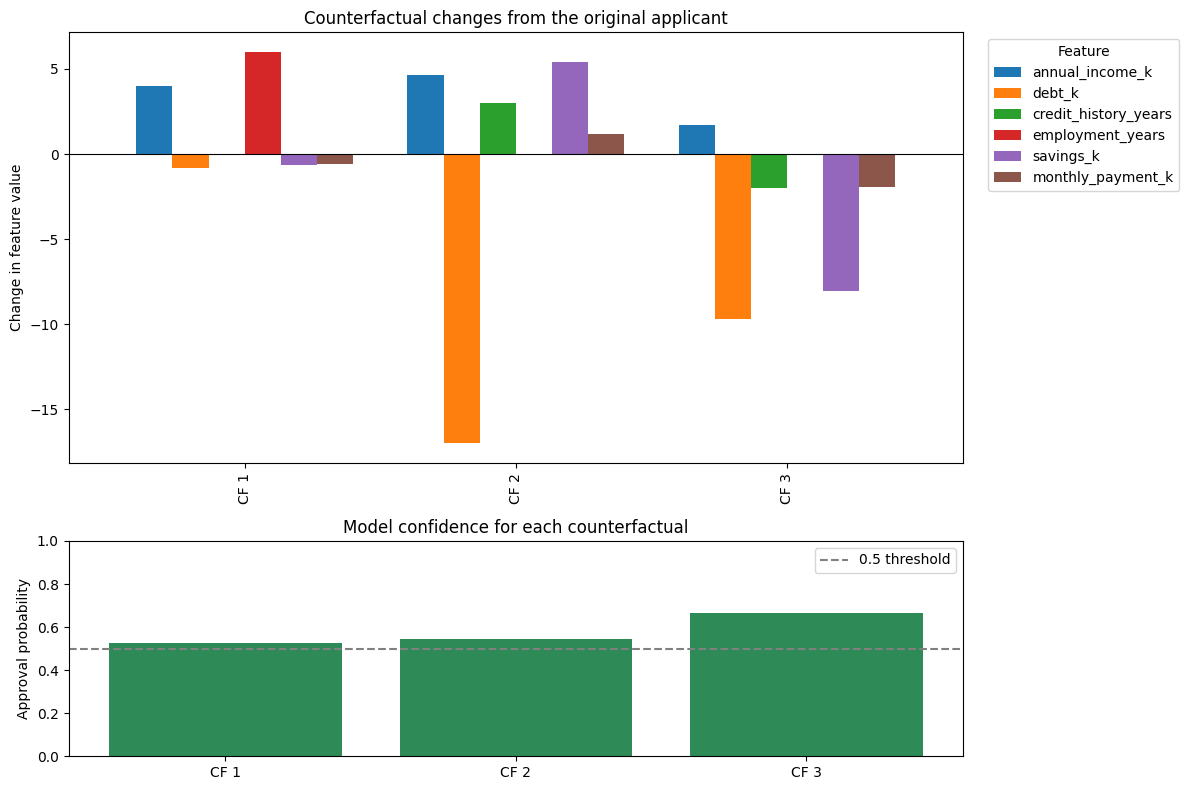

In [22]:
if cf_df is None or cf_df.empty:
    print("No counterfactuals to plot.")
else:
    # Differences from the original applicant
    changes = cf_features[actionable_features].reset_index(drop=True).subtract(
        query.iloc[0][actionable_features],
        axis="columns",
    )

    changes.index = [f"CF {i}" for i in range(1, len(changes) + 1)]

    fig, axes = plt.subplots(
        2, 1,
        figsize=(12, 8),
        gridspec_kw={"height_ratios": [2, 1]},
    )

    changes.plot(kind="bar", ax=axes[0], width=0.8)
    axes[0].axhline(0, color="black", linewidth=0.8)
    axes[0].set_title("Counterfactual changes from the original applicant")
    axes[0].set_ylabel("Change in feature value")
    axes[0].set_xlabel("")
    axes[0].legend(title="Feature", bbox_to_anchor=(1.02, 1), loc="upper left")

    probabilities = cf_features["approval_probability"].reset_index(drop=True)
    axes[1].bar(
        [f"CF {i}" for i in range(1, len(probabilities) + 1)],
        probabilities,
        color="seagreen",
    )
    axes[1].axhline(0.5, color="gray", linestyle="--", label="0.5 threshold")
    axes[1].set_ylim(0, 1)
    axes[1].set_ylabel("Approval probability")
    axes[1].set_title("Model confidence for each counterfactual")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

# 7. Compare methods or feature constraints


# TO-DO's:


DiCE documents random, genetic, and KD-tree options for model-agnostic counterfactual generation. Try changing methods and compare the resulting alternatives.

For a second experiment, change features_to_vary=actionable_features to features_to_vary="all". Then inspect whether any counterfactuals alter the extra features that were not part of the synthetic approval rule. This is a useful way to discuss validity versus plausibility and actionability.